# Phase 4 — Portfolio construction

**Goal.** Combine the survivors into one diversified portfolio, then time that single portfolio. Momentum and betting-against-beta (BAB) are strategies, not assets: to a portfolio each is just a stream of returns, and streams that do not move together mix into a higher Sharpe ratio. The recipe is set once a year from past data only; within the year only the serving size changes.

Development sample only (1926–2018). The 2019+ holdout is never loaded here.

### Key findings

1. **No duplicates among the survivors.** Monthly correlations are −0.30 (market–momentum), −0.14 (market–BAB) and +0.27 (momentum–BAB). In the 10% most volatile months momentum–BAB rises to +0.44, and market–momentum falls to −0.58: the pair moves further apart in crises. No pair crosses 0.7, on the full sample or at any year-end in real time, so nothing is cut.
2. **The first version of the rule nearly cut momentum for being a hedge.** In real time, the crisis correlation between market and momentum reached −0.69 at the end of 1948, and was below −0.65 at nine year-ends between 1946 and 1955. The rule was first written on |ρ|, so a value of −0.71 would have dropped momentum as a "duplicate" of the market. A duplicate is the same bet, and a strongly negative correlation is a hedge, so the rule now cuts only at ρ > +0.7 (a dated change; it changes no result).
3. **Raw ETFs are mostly market; their tilts are not.** MTUM, QUAL and USMV correlate 0.89, 0.98 and 0.89 with SPY. Hedged in real time, their tilts correlate −0.18, −0.10 and +0.02 with SPY. Trading the MTUM tilt means shorting SPY. Per unit of serving size, the inverse-volatility ETF recipe set at the end of 2018 is long 0.69 MTUM and short 0.42 SPY.
4. **Mixing roughly doubles the Sharpe ratio.** Over 1941–2018 the pieces alone score 0.55 (market), 0.60 (momentum) and 0.85 (BAB). The four mixes score 1.14 to 1.17. The weighting scheme matters much less than mixing at all.
5. **Ledoit-Wolf is not what tames mean-variance here.** With three assets and ten years of daily data its shrinkage intensity has a median of 1.7%, and it never moves a weight by more than 1.4 points. The real brakes are the no-negatives rule and the average with 1/N. In 20 of 79 years the mean-variance half gives momentum a weight of zero, mostly in windows that contain a momentum crash.
6. **The primary passes Tests 1 and 4, so Phase 4 passes, but Test 1 only narrowly, and the result is an upper bound.** The primary holds paper BAB, which cannot be traded. For the inverse-volatility mix, φ = 0.514 against a cutoff of 0.5. Test 4 gives α = 4.2% a year (t 6.1), and reward per unit of risk falls from 41 in the calmest quintile to 6 in the wildest. Equal weight (φ 0.26) and shrunk mean-variance (0.47) fail Test 1, as does every market + momentum mix (0.29–0.36). On log variance every mix has φ between 0.62 and 0.71. Level φ is the fragile part, as it was for momentum in Phase 3. Level φ stays the gate; log φ is reported beside it.
7. **The mix passes Test 4 where one of its pieces does not.** On the same 1941–2018 months the market alone fails Test 4 (t 1.91), while every paper mix passes with t between 5.4 and 6.1.
8. **The tradeable portfolio cannot be judged yet.** The ETF track (SPY + MTUM tilt) has 48 months (2015–2018), under the 120-month minimum. Its long-history paper twin (market + momentum, 1937–2018) passes Test 4 but fails Test 1 for every mix, even without October 1987.
9. **The serving size swings widely, so it is capped at 1.5×.** Uncapped, the primary's size has a median of 0.80×, a 99th percentile of 5.2× and a maximum of 11.6× (May 1944), always after calm months. Through 2008–2009 it falls to 0.04×. The cap of 1.5× (set in the plan) binds in 23% of months.
10. **The bar is the buy-and-hold mix (Sharpe 1.14 to 1.17), and it is high.** Timing the primary in real time, with the cap, gives a Sharpe ratio of 1.40 before costs; uncapped, 1.23. The cap *raises* the Sharpe ratio, because the 5–11× sizes after calm months add risk with little reward. This is an upper bound: paper BAB, no costs, and an asset list chosen on the full sample. Cederburg et al. find that real-time timing gains shrink once the Fama-French factors are in the opportunity set, so expect less from a diversified mix.

### How to read this notebook

Each step has the same parts: **what and why**, the **rule**, the **result** (table and plot), and what it **decides**. Numbers quoted in the text refer to the build of 2026-10-17. The tables and plots are recomputed every time the notebook runs.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from src import portfolio as pf
from src import variance as v
from src.config import PROCESSED_DIR
from src.data.load import load_dev

pd.set_option("display.float_format", "{:,.3f}".format, "display.max_columns", 30, "display.width", 200,
              "display.max_colwidth", None)

NAMES = {"mkt": "Market", "mom": "Momentum", "bab": "Betting against beta", "spy": "SPY", "mtum": "MTUM tilt"}
SHORT = {"mkt": "Market", "mom": "Momentum", "bab": "BAB", "spy": "SPY", "mtum": "MTUM tilt"}
COLORS = {"mkt": "#2a78d6", "mom": "#eda100", "bab": "#4a3aa7"}       # same colors as Phases 2 and 3
METHOD_NAMES = {"equal": "Equal weight", "inv_var": "Inverse variance", "inv_vol": "Inverse volatility",
                "shrunk_mv": "Shrunk mean-variance"}
TRACK_NAMES = {"paper": "Paper: market + momentum + BAB", "paper_no_bab": "Paper: market + momentum",
               "etf": "ETF: SPY + MTUM tilt"}
LIGHT, DARK, FAIL = "#86b6ef", "#1c5cab", "#e8e7e1"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
# The primary mix is drawn in ink; the other three in grey, told apart by dash style and label
MIX_STYLE = {"inv_vol": dict(color=INK, ls="-", lw=1.8), "equal": dict(color=MUTED, ls="--", lw=1.2),
             "inv_var": dict(color=MUTED, ls=":", lw=1.4), "shrunk_mv": dict(color=MUTED, ls="-.", lw=1.2)}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})

def sharpe(daily):
    m = v.monthly_table(daily)["ret"]
    return m.mean() / m.std() * np.sqrt(12)

panel = load_dev()                                           # development sample only
MKT_RV = v.monthly_table(panel["mkt"])["rv"]                 # crisis months are ranked on this
REC = {t: pf.recipes(panel, t) for t in pf.TRACKS}           # about 10 seconds
OUT = {t: pf.returns(panel, t, REC[t]) for t in pf.TRACKS}
PAPER = pf.TRACKS["paper"]["assets"]
P = OUT["paper"]
print(f"Development sample: {panel.index[0].date()} to {panel.index[-1].date()}")
for t, o in OUT.items():
    print(f"{TRACK_NAMES[t]:34s} first recipe {REC[t].index[0][0].date()}, p from {o.index[0].date()} to {o.index[-1].date()}")

Development sample: 1926-07-01 to 2018-12-31
Paper: market + momentum + BAB     first recipe 1940-12-31, p from 1941-01-02 to 2018-12-31
Paper: market + momentum           first recipe 1936-12-31, p from 1937-01-02 to 2018-12-31
ETF: SPY + MTUM tilt               first recipe 2014-12-31, p from 2015-01-02 to 2018-12-31


## 1. The rules (fixed before looking)

| Step | What | Rule |
|---|---|---|
| 1 | Remove duplicates | A pair whose monthly returns have ρ > +0.7, on all months **or** on crisis months (the 10% of months with the highest market variance), is a duplicate. Keep the one with the longer history; if the histories are equal, the one with the stronger Phase 2 Test 4 t-stat. Judged on all history up to the as-of date, and only with at least 120 common months (see the changes below). |
| 2 | Choose weights | Four mix versions: equal weight, inverse variance, inverse volatility, shrunk mean-variance. Estimated at each year-end from the last 10 years of daily returns (all history if shorter), then held for the next calendar year. |
| 3 | Combine, then time | $p_t = \sum_i w_i r_{i,t}$ each day. Serving size for a month: $c / RV_{p}$ of the month before, **capped at 1.5×** (Phase 8 re-runs with 1.0×, 2.0× and no cap). $c$ is set with the recipe, so that over the estimation window the uncapped timed mix and the untimed mix have the same variance. Exposure to asset $i$ is size × $w_i$. |
| Pass | Tests 1 and 4 on $p_t$ | Phase 2's thresholds (Ljung-Box below 1% at 20 and 60 lags and φ > 0.5 on **level** RV, with log φ reported beside it; reward per unit of risk falling with rank correlation ≤ −0.7, α > 0 and t > 1.96), on the **primary**: the paper track with inverse-volatility weights. Judged only with at least 120 months of $p_t$. The primary holds paper BAB, which cannot be traded, so a pass is an **upper bound**. |

**Choices I had to make** (the spec leaves them open). Each is written into `src/portfolio.py` before any result:

- **Three tracks.** *Paper* holds market, momentum and BAB, the three factors that pass every factor filter in Phase 3. *ETF* holds what can actually be traded, SPY and MTUM's hedged tilt. *Paper: market + momentum* is the ETF track's long-history twin. It shows what the tradeable set would have done over 80 years. It is reported, not judged.
- **The primary is the paper track.** It is the only track with enough history to judge: the ETF track starts in 2015 and has 48 months.
- **The asset list is fixed.** It is Phase 3's survivor list on the full development sample, so asset *selection* sees the whole sample. Phase 7's walk-forward replaces it with the real-time screen. The construction here takes the list as given.
- **Windows.** Weights, hedge ratios and $c$ use a rolling 10-year window, because Phase 2 found that variance levels drift (Test 6). The duplicate check uses all history up to the as-of date, like the Phase 3 screen, because it asks a structural question.
- **Daily returns for every estimate** (σ̂, Σ̂, μ̂, β). The ETF track would have 12 to 24 monthly observations otherwise, and daily variance is what the timing rule uses.
- **Crisis months are ranked on the market's variance.** The question is whether diversification survives a market crash.
- **MTUM's tilt is hedged with SPY**, the instrument that would be traded, not with the paper market factor. The β comes from the estimation window and is held for the year.
- **"No negative weights"** means the negative elements of $\hat\Sigma^{-1}\hat\mu$ are set to zero before normalizing, not a constrained optimizer. If every element is negative, the mean-variance half falls back to 1/N.
- **The variance forecast is last month's realized variance** (Moreira and Muir's baseline). Phase 6 chooses the forecasting model.
- **The cap is applied after $c$.** $c$ still matches the variance of the uncapped timed mix, so with the cap the timed mix runs below buy-and-hold's volatility. Compare the two on Sharpe ratios, not on raw returns.

**Changes of 2026-10-17 (Step 1), both made after the first run:**

1. **A minimum history.** In the first run the duplicate check had none. The ETF track's MTUM tilt was judged on 20 to 68 months, so its crisis set had 2 to 7 months. A correlation of two points is always ±1, so the tilt was dropped as a "duplicate" of SPY (|ρ| 1.00). The check now needs 120 common months, Phase 3's existing minimum, which guarantees at least 12 crisis months. The paper tracks always had more than that and are unaffected. With fewer months the pair is not judged, and the ETF track keeps both assets.
2. **Only positive correlations count.** The rule was first written on |ρ|. The first run showed the market–momentum crisis correlation reaching −0.69 (Section 2), so a strongly negative pair could have been cut. A duplicate is the same bet; a negative correlation is a hedge. So the cut is now ρ > +0.7. The change was made after seeing that near miss, but no pair crossed either version at any year-end, so no result changes.

The 1.5× cap and the decisions in Section 6 come from the plan or from your calls of 2026-10-17. No other rule changed.

**What I had seen before fixing these.** Phase 2 and Phase 3 results on the full development sample, including Phase 2's equal-weight seven-factor portfolio passing Test 4. And the general knowledge that market and momentum are negatively correlated. The made-up volatilities in Step 2's illustration come from the spec.

In [2]:
display(pd.DataFrame({"value": pf.PORTFOLIO_RULES}))
display(pd.DataFrame({t: {"assets": ", ".join(s["assets"]), "hedge": ", ".join(f"{a} hedged with {h}" for a, h in s["hedge"].items()) or "none",
                          "min months before the first recipe": s["min_months"]} for t, s in pf.TRACKS.items()}).T)
print("Primary:", pf.PRIMARY)

,value
max_corr,0.700
crisis_share,0.100
window_months,120.000
min_months,120.000
etf_min_months,12.000
max_size,1.500


,assets,hedge,min months before the first recipe
paper,"mkt, mom, bab",none,120
paper_no_bab,"mkt, mom",none,120
etf,"spy, mtum",mtum hedged with spy,12


Primary: ('paper', 'inv_vol')


## 2. Step 1 — Remove duplicates

**What and why.** Two assets that move together are one bet counted twice. The rule compares monthly returns, and then compares them again in the 10% most volatile months, because correlations tend to rise in crises. Diversification that disappears in a crash is not diversification.

### The paper survivors

Dropped on the full sample: nothing


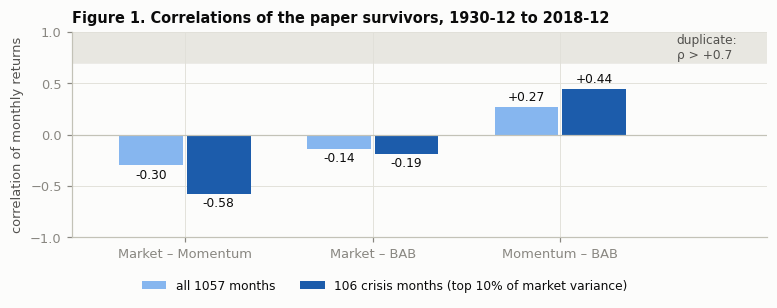

In [3]:
mon = pf.monthly_returns(panel[PAPER].dropna())
full, crisis, n_crisis = pf.correlations(mon, MKT_RV)
pairs = [("mkt", "mom"), ("mkt", "bab"), ("mom", "bab")]
cut = pf.PORTFOLIO_RULES["max_corr"]

fig, ax = plt.subplots(figsize=(7.2, 3.0))
x = np.arange(len(pairs))
for k, (mat, label, color) in enumerate([(full, f"all {len(mon.dropna())} months", LIGHT),
                                         (crisis, f"{n_crisis} crisis months (top 10% of market variance)", DARK)]):
    vals = [mat.loc[a, b] for a, b in pairs]
    ax.bar(x + (k - 0.5) * 0.36, vals, width=0.34, color=color, label=label)
    for xi, val in zip(x, vals):
        ax.text(xi + (k - 0.5) * 0.36, val + (0.03 if val >= 0 else -0.03), f"{val:+.2f}",
                ha="center", va="bottom" if val >= 0 else "top", fontsize=8)
ax.axhspan(cut, 1, color=FAIL, zorder=0)
ax.text(2.62, 0.85, "duplicate:\nρ > +0.7", color=INK2, fontsize=8, va="center")
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(x, [f"{SHORT[a]} – {SHORT[b]}" for a, b in pairs])
ax.set_xlim(-0.6, 3.1); ax.set_ylim(-1, 1); ax.set_ylabel("correlation of monthly returns")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.32), ncol=2, fontsize=8)
ax.set_title(f"Figure 1. Correlations of the paper survivors, {mon.dropna().index[0]} to {mon.index[-1]}")
fig.tight_layout()

history = {a: int(panel[a].count()) for a in PAPER}
print("Dropped on the full sample:", pf.dedupe(mon, MKT_RV, history, lambda a: 0.0) or "nothing")

**Result.** No pair comes near the cutoff, and **nothing is cut**. Market and momentum are negatively correlated (−0.30), market and BAB slightly negative (−0.14), and momentum and BAB slightly positive (+0.27).

**Crises.** Correlations do change in the most volatile months, but not toward duplication. Momentum and BAB do rise together (+0.27 to +0.44), so some of their diversification fades when it is most needed. Market and momentum go the other way (−0.30 to −0.58): in market crashes momentum tends to gain, because it is short the recent losers, which are usually the high-beta stocks. (The same pair is behind momentum's crashes in sharp rebounds, such as 1932 and 2009.)

### In real time

The duplicate check runs at every year-end inside `recipes`, using only history up to that date. Figure 2 shows what it saw.

,all months: most extreme,crisis months: most extreme,year of the crisis extreme
Market – Momentum,-0.57,-0.69,1948
Market – BAB,-0.22,-0.42,1954
Momentum – BAB,+0.46,+0.67,1952


Year-ends with anything dropped: 0
Year-ends with market–momentum crisis correlation below -0.65: 9 (1946–1955)


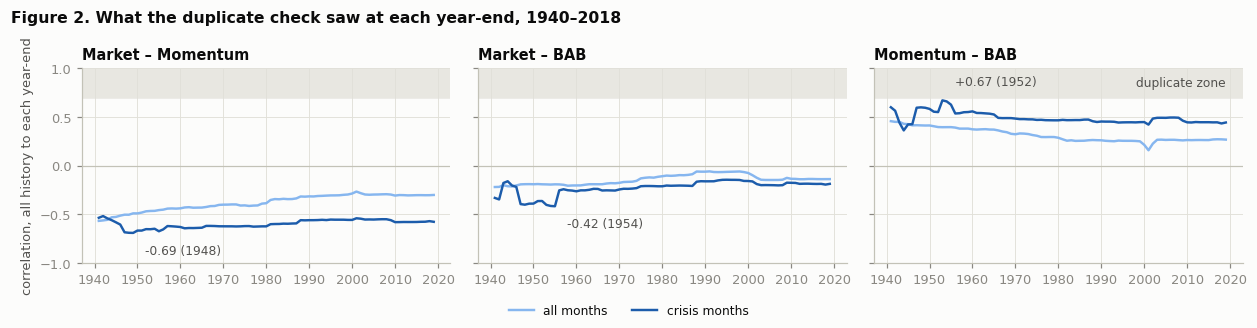

In [4]:
rt = REC["paper"].xs("inv_vol", level="method")
fig, axes = plt.subplots(1, 3, figsize=(11.5, 2.9), sharey=True)
for ax, (a, b) in zip(axes, pairs):
    ax.axhspan(cut, 1, color=FAIL, zorder=0)
    ax.plot(rt.index, rt[f"rho_{a}_{b}"], color=LIGHT, lw=1.6, label="all months")
    ax.plot(rt.index, rt[f"crisis_{a}_{b}"], color=DARK, lw=1.6, label="crisis months")
    k = rt[f"crisis_{a}_{b}"].abs().idxmax()
    ax.annotate(f"{rt.loc[k, f'crisis_{a}_{b}']:+.2f} ({k.year})", (k, rt.loc[k, f"crisis_{a}_{b}"]),
                xytext=(8, 10 if rt.loc[k, f"crisis_{a}_{b}"] > 0 else -14), textcoords="offset points", fontsize=8, color=INK2)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_title(f"{SHORT[a]} – {SHORT[b]}"); ax.set_ylim(-1, 1)
axes[0].set_ylabel("correlation, all history to each year-end")
fig.legend(handles=[Line2D([], [], color=LIGHT, lw=1.6, label="all months"), Line2D([], [], color=DARK, lw=1.6, label="crisis months")],
           loc="lower center", ncol=2, fontsize=8)
axes[2].text(rt.index[-1], 0.85, "duplicate zone", ha="right", va="center", color=INK2, fontsize=8)
fig.suptitle("Figure 2. What the duplicate check saw at each year-end, 1940–2018", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.07, 1, 1))

extreme = lambda s: s.loc[s.abs().idxmax()]
worst = {f"{SHORT[a]} – {SHORT[b]}": {"all months: most extreme": f"{extreme(rt[f'rho_{a}_{b}']):+.2f}",
                                       "crisis months: most extreme": f"{extreme(rt[f'crisis_{a}_{b}']):+.2f}",
                                       "year of the crisis extreme": rt[f"crisis_{a}_{b}"].abs().idxmax().year} for a, b in pairs}
display(pd.DataFrame(worst).T)
print("Year-ends with anything dropped:", int((REC["paper"]["dropped"] != "").sum()))
near = rt.index[rt["crisis_mkt_mom"] < -0.65].year.tolist()
print(f"Year-ends with market–momentum crisis correlation below -0.65: {len(near)} ({near[0]}–{near[-1]})")

**Result.** No pair crosses +0.7 at any year-end, so the real-time portfolio holds the same three assets throughout. But two pairs come close in the crisis months:

- **Market–momentum reaches −0.69 at the end of 1948**, and is below −0.65 at nine year-ends between 1946 and 1955. Under the first version of the rule, written on |ρ|, −0.71 would have dropped momentum, the shorter history, as a "duplicate" of the market. A strongly negative correlation means the two offset each other: that is a hedge, not the same bet. The rule now counts only positive correlations (Section 1), which is why Figure 2 shades only the top of each panel.
- **Momentum–BAB reaches +0.67 in 1952.** That one is a genuine warning, and the current rule would act on it: in the crises of the 1930s and 1940s the two moved together.

Early crisis sets are small (12 months at the first year-end, 106 at the last), so the early correlations are noisy.

### The ETFs: trade the tilt, not the ETF

**What and why.** A long-only factor ETF is mostly market exposure, so it will look like a duplicate of SPY. The fix is to trade the tilt: $\text{tilt}_t = r^{ETF}_t - \beta\, r^{SPY}_t$, with β estimated from past data. Here β is re-estimated at each year-end on all ETF history up to then (at least one year) and held for the next year. Correlations of the tilts therefore start in 2015.

Correlations of the hedged tilts, all months:


,SPY,MTUM tilt,QUAL tilt,USMV tilt
SPY,1.000,-0.177,-0.100,0.023
MTUM tilt,-0.177,1.000,0.286,0.261
QUAL tilt,-0.100,0.286,1.000,0.272
USMV tilt,0.023,0.261,0.272,1.000


Hedged tilts against the paper factors:


,paper momentum,paper BAB
MTUM tilt,0.749,0.316
QUAL tilt,0.284,0.253
USMV tilt,0.267,0.508


Crisis months in the ETF samples: 7 (raw), 5 (tilts); under the 12 needed to judge a pair.


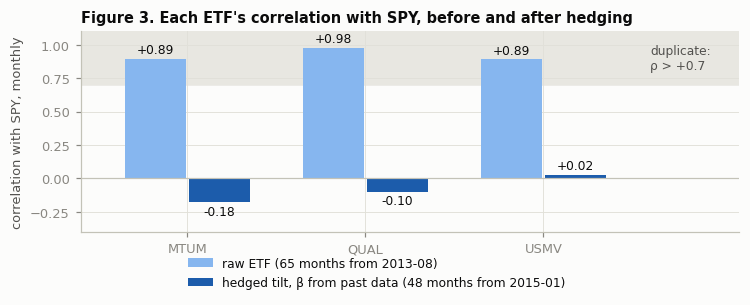

In [5]:
etfs = ["mtum", "qual", "usmv"]
raw = pf.monthly_returns(panel[["spy"] + etfs].dropna())
raw_full, raw_crisis, raw_n = pf.correlations(raw, MKT_RV)
tilts = pd.concat([panel["spy"]] + [pf.realtime_tilt(panel, e).rename(e) for e in etfs], axis=1).dropna()
tm = pf.monthly_returns(tilts)
tilt_full, tilt_crisis, tilt_n = pf.correlations(tm, MKT_RV)

fig, ax = plt.subplots(figsize=(6.8, 3.0))
x = np.arange(len(etfs))
ax.axhspan(cut, 1.1, color=FAIL, zorder=0)
for k, (vals, label, color) in enumerate([
        (raw_full.loc["spy", etfs], f"raw ETF ({len(raw.dropna())} months from {raw.dropna().index[0]})", LIGHT),
        (tilt_full.loc["spy", etfs], f"hedged tilt, β from past data ({len(tm.dropna())} months from {tm.dropna().index[0]})", DARK)]):
    ax.bar(x + (k - 0.5) * 0.36, vals, width=0.34, color=color, label=label)
    for xi, val in zip(x, vals):
        ax.text(xi + (k - 0.5) * 0.36, val + (0.02 if val >= 0 else -0.02), f"{val:+.2f}",
                ha="center", va="bottom" if val >= 0 else "top", fontsize=8)
ax.axhline(0, color=AXIS, lw=0.8)
ax.text(2.6, 0.9, "duplicate:\nρ > +0.7", color=INK2, fontsize=8, va="center")
ax.set_xticks(x, [e.upper() for e in etfs]); ax.set_xlim(-0.6, 3.1); ax.set_ylim(-0.4, 1.1)
ax.set_ylabel("correlation with SPY, monthly")
ax.legend(loc="lower center", bbox_to_anchor=(0.45, -0.34), ncol=1, fontsize=8)
ax.set_title("Figure 3. Each ETF's correlation with SPY, before and after hedging")
fig.tight_layout()

tilt_full.index = tilt_full.columns = ["SPY", "MTUM tilt", "QUAL tilt", "USMV tilt"]
print("Correlations of the hedged tilts, all months:"); display(tilt_full)
vs_paper = pd.concat([tm[etfs], pf.monthly_returns(panel[["mom", "bab"]].loc[tilts.index])], axis=1).dropna().corr().loc[etfs, ["mom", "bab"]]
vs_paper.index = ["MTUM tilt", "QUAL tilt", "USMV tilt"]; vs_paper.columns = ["paper momentum", "paper BAB"]
print("Hedged tilts against the paper factors:"); display(vs_paper)
print(f"Crisis months in the ETF samples: {raw_n} (raw), {tilt_n} (tilts); under the 12 needed to judge a pair.")

**Result.** As expected, the raw ETFs are near-copies of SPY: MTUM 0.89, QUAL 0.98, USMV 0.89. Given enough history, the rule would cut all three as duplicates of SPY, which has the longer history. **Hedged, they are not.** The tilts correlate −0.18 (MTUM), −0.10 (QUAL) and +0.02 (USMV) with SPY, and 0.26 to 0.29 with each other.

**What the tilts are.** MTUM's tilt correlates 0.75 with paper momentum, so it carries a real share of the factor. USMV's tilt correlates only 0.51 with paper BAB.

**Caution.** These are 48 to 65 months, and the crisis sets have 5 and 7 months, well under the 12 the rule needs. So the ETF pairs are reported here, not judged.

### Betting-against-beta has no ETF twin

No liquid ETF copies BAB's levered long-short design. USMV's hedged tilt was the closest candidate, and it failed Phase 3's filter 4 (R² 0.38). Its 0.51 correlation with paper BAB above says the same. **So paper BAB cannot be traded as built**, and the two kinds of track differ:

| Track | Assets | History | Role |
|---|---|---|---|
| Paper | market, momentum, BAB | p from 1941 | **primary**: the only track long enough to judge |
| ETF | SPY, MTUM tilt | p from 2015 | what can actually be traded; reported, under the 120-month minimum |
| Paper: market + momentum | market, momentum | p from 1937 | the ETF track's long-history twin; reported |

**Decides.** No duplicates, so every track keeps its full asset list. The ETF track trades MTUM as its hedged tilt.

## 3. Step 2 — Choose weights

**What and why.** The mix weights $w_i$ set how much of each asset goes into the portfolio. They are separate from the timing step. For zero-cost factors they only set the ratio between the bets; the total size comes in Step 3. Four versions are built, each estimated from past data only and updated once a year:

| Version | Mix weights $w_i$ | Why include it |
|---|---|---|
| Equal weight | 1/N each | No estimation error. DeMiguel, Garlappi and Uppal (2009) show it is hard to beat out of sample. Caveat: for long-short factors it depends on each factor's arbitrary scale |
| Inverse variance | ∝ $1/\hat\sigma_i^2$ | The lowest-risk mix when correlations are zero; best if every piece has the same expected return |
| Inverse volatility | ∝ $1/\hat\sigma_i$ | Equal risk from each piece; best if every piece has the same Sharpe ratio; unaffected by a factor's scale. **The primary test uses this one** |
| Shrunk mean-variance | average of the normalized $\hat\Sigma^{-1}\hat\mu$ and 1/N; Ledoit-Wolf covariance; no negative weights | Theory's best choice, tamed |

### Equal money is not equal risk

With zero correlations, piece $i$'s share of the mix's variance is $w_i^2\sigma_i^2 / \sigma_p^2$. Figure 4 uses made-up volatilities, not estimates: market 16%, momentum 24%, BAB 12%.

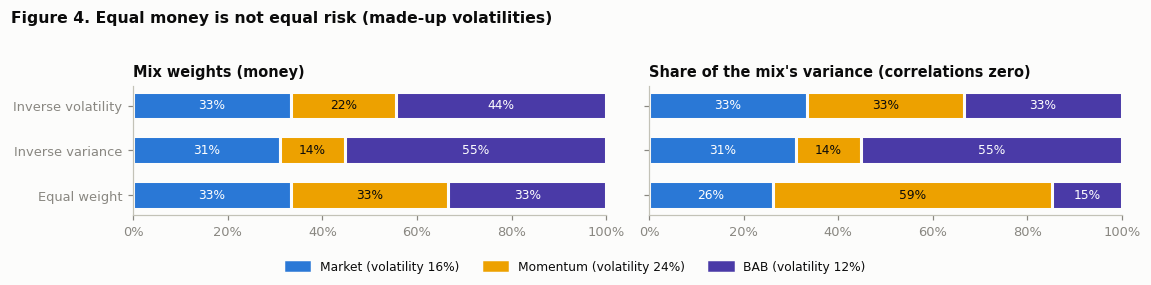

In [6]:
VOLS = pd.Series({"mkt": 0.16, "mom": 0.24, "bab": 0.12})          # illustration only, not estimates
illus = {"Equal weight": pd.Series(1 / 3, VOLS.index), "Inverse variance": 1 / VOLS ** 2, "Inverse volatility": 1 / VOLS}
illus = {k: w / w.sum() for k, w in illus.items()}
risk = {k: (w ** 2 * VOLS ** 2) / (w ** 2 * VOLS ** 2).sum() for k, w in illus.items()}

def stacked(ax, shares, title):
    for i, (name, s) in enumerate(shares.items()):
        left = 0
        for a in VOLS.index:
            ax.barh(i, s[a], left=left, color=COLORS[a], height=0.62, edgecolor=SURFACE, linewidth=2)
            if s[a] > 0.06:
                ax.text(left + s[a] / 2, i, f"{s[a]:.0%}", ha="center", va="center", fontsize=8,
                        color=INK if a == "mom" else "white")
            left += s[a]
    ax.set_yticks(range(len(shares)), list(shares)); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.grid(False)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 2.5), sharey=True)
stacked(axes[0], illus, "Mix weights (money)")
stacked(axes[1], risk, "Share of the mix's variance (correlations zero)")
fig.legend(handles=[Patch(color=COLORS[a], label=f"{SHORT[a]} (volatility {VOLS[a]:.0%})") for a in VOLS.index],
           loc="lower center", ncol=3, fontsize=8)
fig.suptitle("Figure 4. Equal money is not equal risk (made-up volatilities)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.1, 1, 0.94))

**Reading.** With equal money, momentum, the most volatile piece, carries 59% of the risk and BAB only 15%. Inverse variance overshoots the other way, so BAB carries 55%. Only inverse volatility gives each piece the same third of the risk.

### Why inverse volatility is the primary mix

With zero correlations, mean-variance gives $w_i \propto \mu_i / \sigma_i^2$. If every piece pays the same Sharpe ratio $S$, then $\mu_i = S\sigma_i$, and

$$w_i \propto \frac{\mu_i}{\sigma_i^2} = \frac{S\,\sigma_i}{\sigma_i^2} = \frac{S}{\sigma_i}.$$

So inverse volatility is the mean-variance answer when the Sharpe ratios are equal. It needs no estimate of the mean, which is the hard part (next).

It is also immune to a factor's arbitrary scale. Lever a factor 2× and its σ doubles, its weight halves, and its risk stays the same. Equal weights and inverse-variance weights both change with that scale (the unit test `test_inverse_vol_ignores_a_factors_scale_but_equal_and_inverse_variance_do_not` checks this).

### Why mean-variance needs taming

The mean estimate $\hat\mu$ is very noisy, and $\hat\Sigma^{-1}$ turns that noise into extreme weights. How noisy, step by step, for 10 years of monthly returns with 4.5% monthly volatility:

In [7]:
s, n = 0.045, 120
se_mean = 12 * s / np.sqrt(n)                         # annual standard error of the mean
vol, se_vol = s * np.sqrt(12), s * np.sqrt(12) / np.sqrt(2 * n)
steps = pd.Series({
    "1. monthly volatility σ": f"{s:.1%}",
    "2. months of data n": f"{n}",
    "3. standard error of the monthly mean, σ / √n": f"{s / np.sqrt(n):.2%} a month",
    "4. ... in annual terms (× 12)": f"{se_mean:.1%} a year",
    "5. 95% interval for the annual mean (± 1.96 standard errors)": f"± {1.96 * se_mean:.1%} a year",
    "6. so a true premium of 6% a year is estimated anywhere in": f"{0.06 - 1.96 * se_mean:+.1%} to {0.06 + 1.96 * se_mean:+.1%}",
    "7. for comparison, the annual volatility σ√12": f"{vol:.1%}",
    "8. 95% interval for the volatility (standard error σ√12 / √(2n))": f"± {1.96 * se_vol:.1%}, i.e. {vol - 1.96 * se_vol:.1%} to {vol + 1.96 * se_vol:.1%}",
}, name="value").to_frame()
display(steps)

,value
1. monthly volatility σ,4.5%
2. months of data n,120
"3. standard error of the monthly mean, σ / √n",0.41% a month
4. ... in annual terms (× 12),4.9% a year
5. 95% interval for the annual mean (± 1.96 standard errors),± 9.7% a year
6. so a true premium of 6% a year is estimated anywhere in,-3.7% to +15.7%
"7. for comparison, the annual volatility σ√12",15.6%
8. 95% interval for the volatility (standard error σ√12 / √(2n)),"± 2.0%, i.e. 13.6% to 17.6%"


**Reading.** Ten years of data cannot pin down even the sign of a 6% premium: the interval runs from −3.7% to +15.7% a year. The same data pins down the volatility to within ±2 points. That is why the weight schemes that use only σ are stable, and mean-variance is not.

Figure 5 shows what that noise does to the weights. It simulates 2,000 ten-year samples of monthly returns from a world where the right answer is known. The three pieces have the made-up volatilities above, zero correlations and the same Sharpe ratio, 0.4. In that world the best weights are exactly inverse volatility: 33% market, 22% momentum, 44% BAB.

,5th–95th percentile of the BAB weight,samples with a weight of zero,average distance from the best weights
"Mean-variance, no negatives",0% – 77%,28%,26%
Shrunk mean-variance,17% – 55%,0%,15%
Inverse volatility,41% – 48%,0%,2%


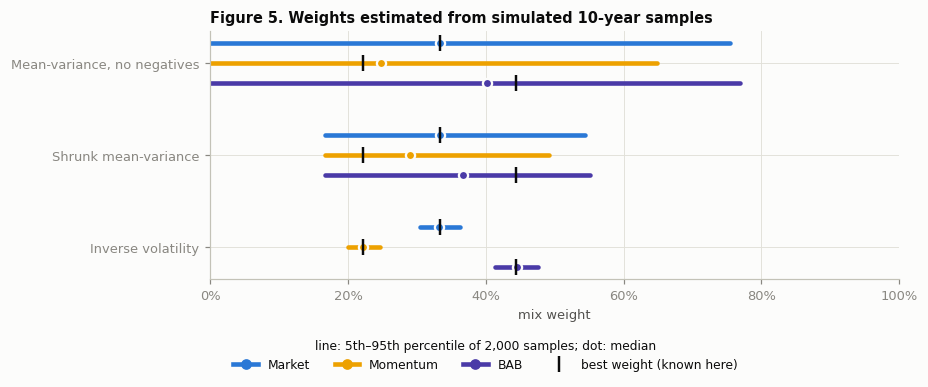

In [8]:
from sklearn.covariance import LedoitWolf

def mv_no_negatives(x):
    raw = np.linalg.solve(LedoitWolf().fit(x.to_numpy()).covariance_, x.mean().to_numpy()).clip(min=0)
    return pd.Series(raw / raw.sum() if raw.sum() > 0 else 1 / len(raw), x.columns)

rng = np.random.default_rng(0)
true = (1 / VOLS) / (1 / VOLS).sum()
sim = {"Mean-variance, no negatives": [], "Shrunk mean-variance": [], "Inverse volatility": []}
for _ in range(2000):
    x = pd.DataFrame(rng.normal(0.4 * VOLS / 12, VOLS / np.sqrt(12), (120, 3)), columns=VOLS.index)
    sim["Mean-variance, no negatives"].append(mv_no_negatives(x))
    sim["Shrunk mean-variance"].append(pf.mix_weights(x, "shrunk_mv"))
    sim["Inverse volatility"].append(pf.mix_weights(x, "inv_vol"))
sim = {k: pd.DataFrame(w) for k, w in sim.items()}

fig, ax = plt.subplots(figsize=(8.5, 3.7))
for i, (name, w) in enumerate(sim.items()):
    for j, a in enumerate(VOLS.index):
        y = i + (j - 1) * 0.22
        lo, mid, hi = w[a].quantile([0.05, 0.5, 0.95])
        ax.plot([lo, hi], [y, y], color=COLORS[a], lw=3, solid_capstyle="round")
        ax.plot(mid, y, "o", color=COLORS[a], ms=6, mec=SURFACE, mew=1.5)
        ax.plot(true[a], y, "|", color=INK, ms=11, mew=1.6)
ax.set_yticks(range(len(sim)), list(sim)); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_xlabel("mix weight")
ax.legend(handles=[Line2D([], [], color=COLORS[a], lw=3, marker="o", label=SHORT[a]) for a in VOLS.index]
          + [Line2D([], [], color=INK, ls="", marker="|", ms=11, mew=1.6, label="best weight (known here)")],
          loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=4, fontsize=8, title="line: 5th–95th percentile of 2,000 samples; dot: median", title_fontsize=8)
ax.set_title("Figure 5. Weights estimated from simulated 10-year samples")
fig.tight_layout()

summary = pd.DataFrame({k: {"5th–95th percentile of the BAB weight": f"{w['bab'].quantile(.05):.0%} – {w['bab'].quantile(.95):.0%}",
                            "samples with a weight of zero": f"{(w.min(axis=1) < 1e-12).mean():.0%}",
                            "average distance from the best weights": f"{(w - true).abs().sum(axis=1).mean() / 2:.0%}"}
                        for k, w in sim.items()}).T
display(summary)

**Reading.** Inverse volatility lands close to the best weights in every sample. Mean-variance, even with negatives set to zero, scatters across most of the range, and it gives at least one piece no weight at all in 28% of the samples. Averaging with 1/N halves that scatter and removes the zeros. Mean-variance still ends further from the truth than inverse volatility, which never looks at the mean. The "average distance" counts how much of the money sits in the wrong place: half the sum of absolute differences from the best weights.

### The weights in real time

Every year-end, each version is estimated from the last 10 years of daily returns and held for the next calendar year. Figure 6 shows the result for the paper track.

Shrunk mean-variance: years where the mean-variance half gives an asset zero weight: {'Market': 0, 'Momentum': 20, 'BAB': 0} of 79
  momentum's zero years: [1941, 1942, 1943, 1944, 1945, 1946, 1947, 1948, 1949, 1959, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]


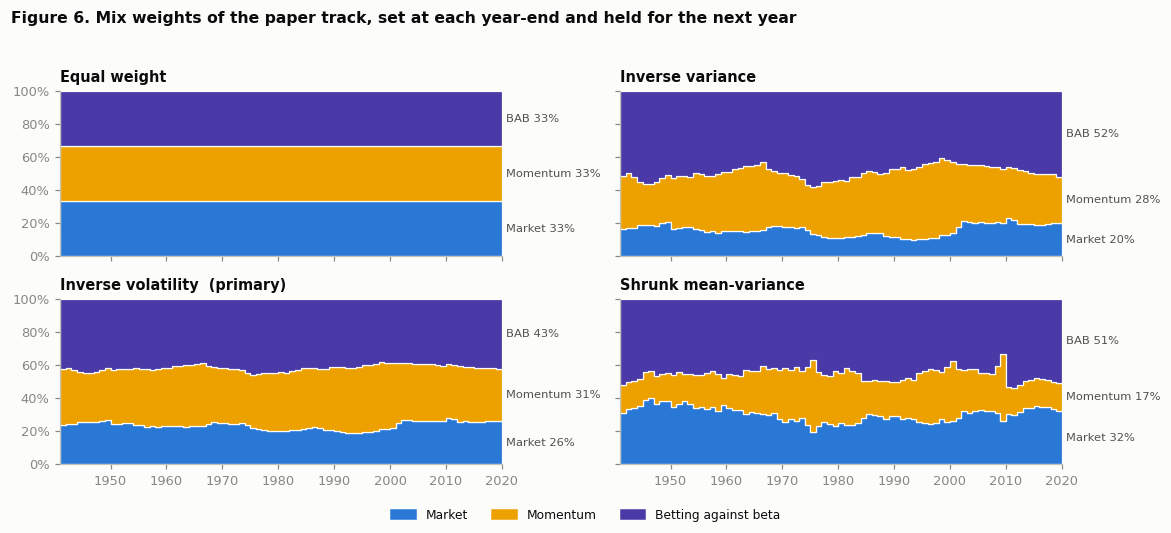

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 4.8), sharex=True, sharey=True)
for ax, m in zip(axes.flat, pf.METHODS):
    w = REC["paper"].xs(m, level="method")[[f"w_{a}" for a in PAPER]]
    years = list(w.index.year + 1) + [w.index.year[-1] + 2]                    # held the year after the as-of date
    vals = np.vstack([np.append(w[f"w_{a}"].to_numpy(), w[f"w_{a}"].iloc[-1]) for a in PAPER])
    ax.stackplot(years, vals, colors=[COLORS[a] for a in PAPER], step="post", edgecolor=SURFACE, linewidth=0.8)
    for a, mid in zip(PAPER, np.cumsum(vals[:, -2]) - vals[:, -2] / 2):
        ax.text(years[-1] + 0.8, mid, f"{SHORT[a]} {vals[PAPER.index(a), -2]:.0%}", va="center", fontsize=7.5, color=INK2)
    ax.set_title(METHOD_NAMES[m] + ("  (primary)" if m == pf.PRIMARY[1] else ""))
    ax.set_xlim(years[0], years[-1]); ax.set_ylim(0, 1); ax.grid(False)
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
fig.legend(handles=[Patch(color=COLORS[a], label=NAMES[a]) for a in PAPER], loc="lower center", ncol=3, fontsize=8)
fig.suptitle("Figure 6. Mix weights of the paper track, set at each year-end and held for the next year",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.05, 0.93, 0.95))

w_mv = REC["paper"].xs("shrunk_mv", level="method")[[f"w_{a}" for a in PAPER]]
zero = (w_mv - 1 / 6).abs() < 1e-9                                           # mean-variance half gave zero
print(f"Shrunk mean-variance: years where the mean-variance half gives an asset zero weight: "
      f"{ {SHORT[a]: int(zero[f'w_{a}'].sum()) for a in PAPER} } of {len(w_mv)}")
print("  momentum's zero years:", [d.year + 1 for d in zero.index[zero["w_mom"]]])

**Reading.**

- **Inverse volatility (the primary) is steady.** At the end of 2018 it is market 26%, momentum 31%, BAB 43%. BAB has the lowest volatility, so it gets the most money. Over 79 year-ends each weight stays within a band of about ten points (market 19–28%, momentum 30–41%, BAB 38–46%).
- **Inverse variance leans hardest on BAB** (41–59%) and gives the market only 10–23%.
- **Shrunk mean-variance jumps.** Its mean-variance half sets momentum to zero in 20 of 79 years: 1941–1949, 1959 and 2010–2019. Except 1959, those are the years whose 10-year windows contain a momentum crash (1932 and 2009). In those years momentum's weight drops to 1/6, the floor that the 1/N half guarantees.

**The actual risk shares.** Table below: the end-2018 recipes, with each piece's share of the mix's variance, correlations included. The risk contribution of piece $i$ is $w_i(\hat\Sigma w)_i / w'\hat\Sigma w$; the shares add up to 100%.

In [10]:
asof = REC["paper"].index[-1][0]
win = panel[PAPER].dropna().loc[asof - pd.DateOffset(months=pf.PORTFOLIO_RULES["window_months"]):asof].iloc[1:]
cov = win.cov()
rows = {}
for m in pf.METHODS:
    w = REC["paper"].loc[(asof, m), [f"w_{a}" for a in PAPER]].astype(float).set_axis(PAPER)
    rc = w * (cov @ w) / (w @ cov @ w)
    rows[METHOD_NAMES[m]] = {**{f"money: {SHORT[a]}": w[a] for a in PAPER}, **{f"risk: {SHORT[a]}": rc[a] for a in PAPER}}
display(pd.DataFrame(rows).T.style.format("{:.0%}"))
print(f"Window {win.index[0].date()} to {asof.date()}: annual volatility",
      {SHORT[a]: f"{win[a].std() * np.sqrt(252):.1%}" for a in PAPER}, "| annual mean",
      {SHORT[a]: f"{win[a].mean() * 252:+.1%}" for a in PAPER})
lw = {d.year: LedoitWolf().fit(panel[PAPER].dropna().loc[d - pd.DateOffset(months=120):d].iloc[1:].to_numpy()).shrinkage_
      for d in REC["paper"].index.get_level_values("asof").unique()}
print(f"Ledoit-Wolf shrinkage intensity across the 79 year-ends: {min(lw.values()):.1%} to {max(lw.values()):.1%}")

,money: Market,money: Momentum,money: BAB,risk: Market,risk: Momentum,risk: BAB
Equal weight,33%,33%,33%,29%,49%,22%
Inverse variance,20%,28%,52%,-3%,45%,58%
Inverse volatility,26%,31%,43%,9%,51%,40%
Shrunk mean-variance,32%,17%,51%,27%,24%,50%


Window 2009-01-02 to 2018-12-31: annual volatility {'Market': '17.0%', 'Momentum': '14.4%', 'BAB': '10.5%'} | annual mean {'Market': '+13.8%', 'Momentum': '-2.1%', 'BAB': '+10.4%'}
Ledoit-Wolf shrinkage intensity across the 79 year-ends: 0.7% to 12.4%


**Reading.** With real correlations, inverse volatility no longer splits the risk into thirds. In the 2009–2018 window the market correlates −0.34 with both momentum and BAB, while momentum and BAB correlate +0.39. So the market offsets the other two, and its share of the risk shrinks to 9% (and below zero under inverse variance, where adding a little market *lowers* the mix's variance). Momentum and BAB add to each other's risk, so momentum carries about half. The window also shows why mean-variance is fragile: momentum's mean over 2009–2018 is negative (−2.1% a year, after its 2009 crash), so mean-variance wants none of it.

**Ledoit-Wolf barely matters here.** It shrinks a noisy covariance toward a simple target, and how much it shrinks depends on how many assets there are relative to observations. With 3 assets and about 2,500 daily returns, the intensity has a median of 1.7% across the 79 year-ends. It exceeds 5% only in 1944–1948 and 1992–1996, with a maximum of 12.4% in 1948. Swapping in the plain sample covariance changes no shrunk mean-variance weight by more than 1.4 points. So the taming in the "shrunk" version comes almost entirely from the no-negatives rule and the 1/N average.

**Decides.** The four versions are built at every year-end for every track. The primary is inverse volatility.

## 4. Step 3 — Combine, then time

**What and why.** The combined return is $p_t = \sum_i w_i r_{i,t}$. The timing rule is applied to $p_t$ using $p_t$'s own variance forecast: one forecast and one size for the whole mix,

$$\text{size}_t = \min\left(\frac{c}{\hat\sigma^2_{p,t}},\ 1.5\right), \qquad \text{exposure to asset } i = \text{size}_t \times w_i .$$

The recipe stays fixed for the year; only the serving size changes. Combining first means timing the variance that is actually borne, correlations included. Timing each piece separately ignores how the pieces offset. Moreira and Muir also apply the rule to combined factor portfolios. The other order is tested in Phase 8.

### The combined portfolio

Annual volatility of p: {'Equal weight': '7.1%', 'Inverse variance': '7.2%', 'Inverse volatility': '7.0%', 'Shrunk mean-variance': '7.1%'}


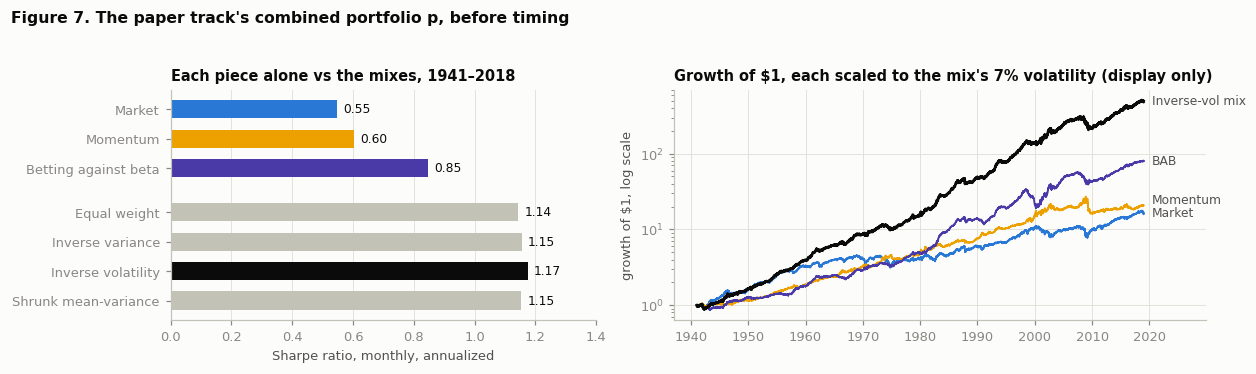

In [11]:
start = P.index[0]
sr = {NAMES[a]: sharpe(panel[a].loc[start:]) for a in PAPER}
sr.update({METHOD_NAMES[m]: sharpe(P[(m, "p")]) for m in pf.METHODS})

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
colors = [COLORS[a] for a in PAPER] + [INK if m == pf.PRIMARY[1] else AXIS for m in pf.METHODS]
y = np.arange(len(sr))[::-1] + np.array([0.5] * 3 + [0] * 4)                   # a gap between pieces and mixes
ax.barh(y, list(sr.values()), color=colors, height=0.62)
for yi, (k, val) in zip(y, sr.items()):
    ax.text(val + 0.02, yi, f"{val:.2f}", va="center", fontsize=8)
ax.set_yticks(y, list(sr)); ax.set_xlim(0, 1.4); ax.grid(axis="y", visible=False)
ax.set_xlabel("Sharpe ratio, monthly, annualized")
ax.set_title(f"Each piece alone vs the mixes, {start.year}–2018")

ax = axes[1]
target = v.monthly_table(P[("inv_vol", "p")])["ret"].std()
ends = {}
for k, r in [(a, panel[a].loc[start:]) for a in PAPER] + [("mix", P[("inv_vol", "p")])]:
    g = (1 + r * target / v.monthly_table(r)["ret"].std()).cumprod()       # display only: the mix's volatility
    ax.plot(g.index, g, **(dict(color=INK, lw=1.8) if k == "mix" else dict(color=COLORS[k], lw=1.2)))
    ends[k] = np.log10(g.iloc[-1])
last = -np.inf
for k in sorted(ends, key=ends.get):                                          # direct labels, kept 0.18 decades apart
    last = max(ends[k], last + 0.18)
    ax.text(P.index[-1] + pd.Timedelta(days=500), 10 ** last, "Inverse-vol mix" if k == "mix" else SHORT[k],
            va="center", fontsize=8, color=INK2)
ax.set_yscale("log"); ax.set_ylabel("growth of $1, log scale"); ax.set_xlim(right=P.index[-1] + pd.Timedelta(days=4000))
ax.set_title("Growth of $1, each scaled to the mix's 7% volatility (display only)")
fig.suptitle("Figure 7. The paper track's combined portfolio p, before timing", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))

print("Annual volatility of p:", {METHOD_NAMES[m]: f"{v.monthly_table(P[(m, 'p')])['ret'].std() * np.sqrt(12):.1%}" for m in pf.METHODS})

**Result.** **Mixing roughly doubles the Sharpe ratio.** On its own, each piece has a Sharpe ratio of 0.55 to 0.85 over 1941–2018. Each mix has 1.14 to 1.17. The weights were set in real time, so this is not hindsight about the mix, although the asset list is (Section 1). The four versions are close together, and inverse volatility is the highest by a small margin. The gain comes from the low and negative correlations of Step 1, not from the choice of weights. At the same 7% volatility, $1 in the mix grows to $491 by 2018, against $16 in the market and $80 in BAB (right panel).

### Tests 1 and 4 on $p_t$

**What and why.** Phase 2 tested each asset alone, but the strategy trades the mix. Timing earns alpha only if the *mix's* reward per unit of risk falls when the *mix's* risk rises. One strong factor does not guarantee that, because the mix's variance is not any single piece's variance. So the two tests that decide whether timing can work are re-run on $p_t$ itself:

- **Test 1 (predictable risk):** Ljung-Box on daily $p^2$ rejects at 1% at 20 and 60 lags, and the monthly AR(1) slope of RV, φ, is above 0.5.
- **Test 4 (exploitable link):** the reward per unit of risk of next month falls across quintiles of this month's variance (rank correlation ≤ −0.7, and lower in the wildest quintile than the calmest), and the spanning regression $\frac{c}{RV_t}p_{t+1} = \alpha + \beta p_{t+1} + \varepsilon$ gives α > 0 with t > 1.96 (White standard errors).

**Rule.** Phase 4 passes if both tests pass on the primary $p_t$ (paper track, inverse volatility). Every other row is reported, not judged.

In [12]:
rows = {}
for t in pf.TRACKS:
    for m in pf.METHODS:
        rows[(TRACK_NAMES[t], METHOD_NAMES[m])] = pf.tests(OUT[t][(m, "p")])
for a in PAPER:
    rows[(f"Each piece alone, from {start.year}", NAMES[a])] = pf.tests(panel[a].loc[start:])
T = pd.DataFrame(rows).T
T.index.names = ["series", "mix"]
show = T[["start", "months", "phi", "phi_log", "t1", "spearman", "sort_ok", "alpha", "t_alpha", "t4", "judged", "pass"]]
display(show.style.format({"phi": "{:.3f}", "phi_log": "{:.3f}", "spearman": "{:+.1f}", "alpha": "{:+.1%}", "t_alpha": "{:.2f}"})
        .apply(lambda r: ["font-weight: bold"] * len(r) if r.name == (TRACK_NAMES["paper"], METHOD_NAMES["inv_vol"]) else [""] * len(r), axis=1))
primary = T.loc[(TRACK_NAMES[pf.PRIMARY[0]], METHOD_NAMES[pf.PRIMARY[1]])]
print(f"PHASE 4 PASS RULE (primary: {pf.PRIMARY}): Test 1 {'pass' if primary['t1'] else 'FAIL'}, "
      f"Test 4 {'pass' if primary['t4'] else 'FAIL'} -> {'PASS' if primary['pass'] else 'FAIL'}"
      " (an upper bound: the paper track holds BAB, which cannot be traded)")
print("Ljung-Box p-values: largest across all rows", f"{T[['p20', 'p60']].to_numpy().max():.1e}")

PHASE 4 PASS RULE (primary: ('paper', 'inv_vol')): Test 1 pass, Test 4 pass -> PASS (an upper bound: the paper track holds BAB, which cannot be traded)
Ljung-Box p-values: largest across all rows 1.5e-70


**Result: the primary passes, so Phase 4 passes, as an upper bound.** The paper track holds BAB, which has no tradeable stand-in, so this is what the strategy could do at best, not what can be traded. Its φ is 0.514, just above the 0.5 cutoff. Its spanning α is 4.2% a year with t = 6.1, and its reward per unit of risk falls with risk (rank correlation −0.8). Ljung-Box rejects with p ≈ 0 in every row, so every Test 1 verdict comes down to φ.

**Test 4 is strong everywhere; Test 1 is not.**

- **All four paper mixes pass Test 4** (α 3.6–5.0%, t 5.4–6.1), and so do the market + momentum mixes (t 4.5–5.8).
- **The mix passes where a piece does not.** On the same 1941–2018 months the market alone fails Test 4 (t 1.91). Momentum and BAB pass.
- **Test 1 splits the mixes.** Inverse variance (φ 0.67) and inverse volatility (0.51) pass. Equal weight (0.26) and shrunk mean-variance (0.47) fail. So does every market + momentum mix (0.29–0.36).
- **On log variance every mix is persistent.** φ on log RV is 0.62–0.71 for all eight paper mixes. The level φ is what fails, and Phase 2 and 3 showed why: one spike month dominates a regression on levels.

Figure 8 shows the quintile sorts behind Test 4; the table after it shows the spike months behind Test 1.

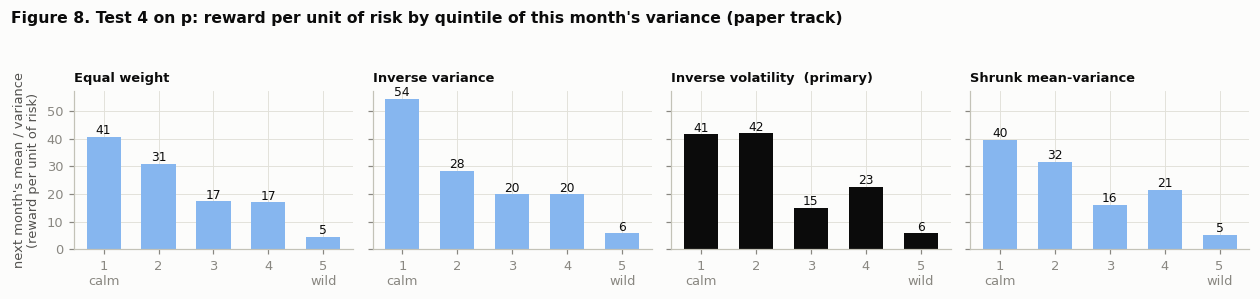

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(11.5, 2.7), sharey=True)
for ax, m in zip(axes, pf.METHODS):
    tab = v.t4_sort(v.monthly_table(P[(m, "p")]))
    ax.bar(tab.index.astype(int), tab["ratio"], color=INK if m == pf.PRIMARY[1] else LIGHT, width=0.62)
    for q, val in tab["ratio"].items():
        ax.text(int(q), val + 1, f"{val:.0f}", ha="center", fontsize=8)
    ax.set_xticks([1, 2, 3, 4, 5], ["1\ncalm", "2", "3", "4", "5\nwild"])
    ax.set_title(METHOD_NAMES[m] + ("  (primary)" if m == pf.PRIMARY[1] else ""), fontsize=8.5)
axes[0].set_ylabel("next month's mean / variance\n(reward per unit of risk)")
fig.suptitle("Figure 8. Test 4 on p: reward per unit of risk by quintile of this month's variance (paper track)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))

In [14]:
def phi_without(rv, months):
    # AR(1) slope of monthly RV, leaving out every pair (t, t+1) that touches one of `months`
    z, y = rv.shift(1), rv
    keep = z.notna() & ~z.index.isin(months) & ~(z.index - 1).isin(months) & ~y.index.isin(months)
    return np.cov(z[keep], y[keep])[0, 1] / z[keep].var(ddof=1)

oct87 = pd.PeriodIndex(["1987-10"], freq="M")
rows = {}
for t in ["paper", "paper_no_bab"]:
    for m in pf.METHODS:
        mon = v.monthly_table(OUT[t][(m, "p")])
        top = mon["rv"].nlargest(3)
        rows[(TRACK_NAMES[t], METHOD_NAMES[m])] = {
            "phi": phi_without(mon["rv"], []), "without Oct 1987": phi_without(mon["rv"], oct87),
            "without its 3 wildest months": phi_without(mon["rv"], top.index), "phi on log RV": T.loc[(TRACK_NAMES[t], METHOD_NAMES[m]), "phi_log"],
            "its 3 wildest months": ", ".join(str(p) for p in top.index), "wildest / median RV": top.iloc[0] / mon["rv"].median()}
display(pd.DataFrame(rows).T.style.format({"phi": "{:.3f}", "without Oct 1987": "{:.3f}", "without its 3 wildest months": "{:.3f}",
                                           "phi on log RV": "{:.3f}", "wildest / median RV": "{:.0f}×"}))

**Reading.**

- **Figure 8.** In every paper mix the calm quintiles earn several times the reward per unit of risk of the wildest quintile (for the primary, 41 and 42 against 6). The pattern is not perfectly monotone; the third quintile dips below the fourth. That is why the rank correlations are −0.8 to −1.0 rather than exactly −1.
- **The spike months.** A month like October 1987 has 50–90 times the median variance. In a regression on levels, that single point and its neighbour carry much of the slope. Removing October 1987 raises the primary's φ from 0.51 to 0.60, and equal weight's from 0.26 to 0.42. Removing each mix's three wildest months (October 1987, October 2008, March–April 2009) moves φ in both directions. So the primary's pass on Test 1 depends on a handful of months, just as momentum's did in Phase 3.
- **Market + momentum fails for a broader reason.** Even without October 1987 its φ stays at 0.41–0.44. On logs it is 0.64–0.67, persistent by any standard, so its variance is predictable in the ordinary sense. It fails only the level rule.

**If $p_t$ had failed.** The spec says to keep the primary test unchanged, rather than switching to timing each piece after seeing the result, which would choose the test from the data. That did not happen: the primary passes. Equal weight, shrunk mean-variance and market + momentum fail Test 1. The likely explanation is spike months in a level regression, not unpredictable risk. Timing the pieces separately keeps its Phase 8 check.

### The serving size

The managed portfolio holds size × $w_i$ of each asset. Figure 9 shows the size for the primary, with and without the 1.5× cap, and what it does to the exposures through 2008–2009.

Information, not a test: real-time weights and c, before costs, paper BAB, asset list from the full sample.


,"median size, uncapped",99th percentile,largest,month of the largest,months capped,Sharpe: buy-and-hold p,"Sharpe: timed, uncapped","Sharpe: timed, capped",volatility: p,"volatility: timed, capped"
Equal weight,0.82×,5.0×,9.9×,1942-10,23%,1.14,1.28,1.33,7.1%,5.5%
Inverse variance,0.86×,5.8×,8.3×,1944-12,27%,1.15,1.31,1.40,7.2%,5.6%
Inverse volatility,0.80×,5.2×,11.6×,1944-05,23%,1.17,1.23,1.40,7.0%,5.3%
Shrunk mean-variance,0.82×,4.3×,11.6×,1976-08,23%,1.15,1.28,1.37,7.1%,5.4%


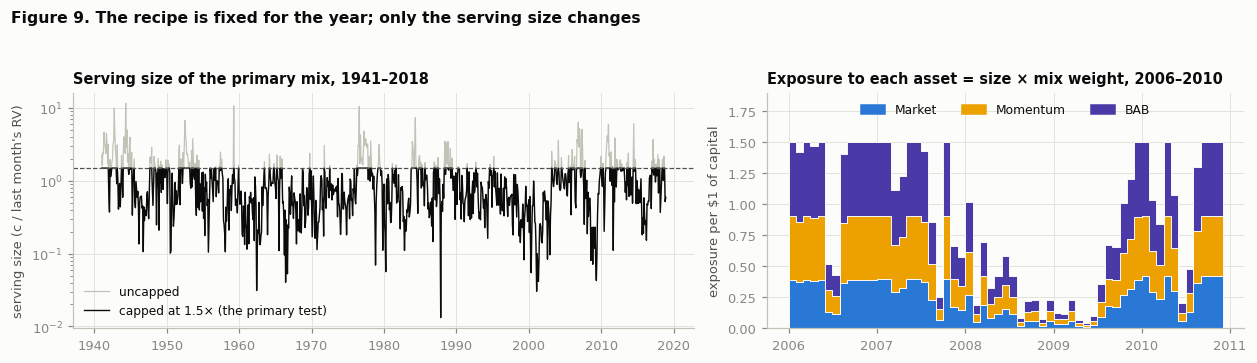

In [15]:
FREE = pf.returns(panel, "paper", REC["paper"], max_size=None)                  # no cap, for comparison
CAP = pf.PORTFOLIO_RULES["max_size"]
monthly = lambda s_: s_.groupby(s_.index.to_period("M")).first()
size, free = monthly(P[("inv_vol", "scale")]), monthly(FREE[("inv_vol", "scale")])
w = REC["paper"].xs("inv_vol", level="method")[[f"w_{a}" for a in PAPER]]
w.index = (w.index.year + 1).astype(str)                                       # recipe -> its holding year
expo = pd.DataFrame({a: size * w[f"w_{a}"].reindex(size.index.year.astype(str)).to_numpy() for a in PAPER}, index=size.index)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
ax.plot(free.index.to_timestamp(), free, color=AXIS, lw=0.8, label="uncapped")
ax.plot(size.index.to_timestamp(), size, color=INK, lw=0.9, label=f"capped at {CAP}× (the primary test)")
ax.axhline(CAP, color=INK2, lw=0.8, ls="--")
ax.set_yscale("log"); ax.set_ylabel("serving size (c / last month's RV)")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Serving size of the primary mix, 1941–2018")
ax = axes[1]
z = expo.loc["2006-01":"2010-12"]
ax.stackplot(z.index.to_timestamp(), z.T.to_numpy(), colors=[COLORS[a] for a in PAPER], step="post", edgecolor=SURFACE, linewidth=0.6)
ax.set_ylabel("exposure per $1 of capital"); ax.set_title("Exposure to each asset = size × mix weight, 2006–2010")
ax.set_ylim(0, 1.9)
ax.legend(handles=[Patch(color=COLORS[a], label=SHORT[a]) for a in PAPER], loc="upper center", ncol=3, fontsize=8)
fig.suptitle("Figure 9. The recipe is fixed for the year; only the serving size changes", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))

stats = {}
for m in pf.METHODS:
    s_ = monthly(FREE[(m, "scale")])
    stats[METHOD_NAMES[m]] = {"median size, uncapped": s_.median(), "99th percentile": s_.quantile(0.99), "largest": s_.max(),
                              "month of the largest": str(s_.idxmax()), "months capped": (s_ > CAP).mean(),
                              "Sharpe: buy-and-hold p": sharpe(P[(m, "p")]), "Sharpe: timed, uncapped": sharpe(FREE[(m, "managed")]),
                              "Sharpe: timed, capped": sharpe(P[(m, "managed")]),
                              "volatility: p": v.monthly_table(P[(m, "p")])["ret"].std() * np.sqrt(12),
                              "volatility: timed, capped": v.monthly_table(P[(m, "managed")])["ret"].std() * np.sqrt(12)}
print("Information, not a test: real-time weights and c, before costs, paper BAB, asset list from the full sample.")
display(pd.DataFrame(stats).T.style.format({"median size, uncapped": "{:.2f}×", "99th percentile": "{:.1f}×", "largest": "{:.1f}×",
                                            "months capped": "{:.0%}", "Sharpe: buy-and-hold p": "{:.2f}",
                                            "Sharpe: timed, uncapped": "{:.2f}", "Sharpe: timed, capped": "{:.2f}",
                                            "volatility: p": "{:.1%}", "volatility: timed, capped": "{:.1%}"}))

**Reading.**

- **Uncapped, the size swings over a wide range.** For the primary it is 0.80× in the median month, 5.2× at the 99th percentile and 11.6× at the most (May 1944). The largest sizes come after unusually calm months. That is why the cap exists: **at 1.5× it binds in 23% of months** for the primary (23–27% across the four mixes).
- **2006–2010 in the right panel.** After the calm of late 2006 the uncapped size is 3–6×, and the cap holds it at 1.5×. Through the crisis the size falls to 0.07× in November 2008 and 0.04× in May 2009, after momentum's crash. Every exposure falls at once, because the recipe is fixed. By late 2010 the size is back at the cap.
- **The timed Sharpe ratio (information, not a test).** With weights and $c$ set from past data only, timing the primary gives 1.23 uncapped and **1.40 capped**, against 1.17 for buy-and-hold. The other mixes rise to 1.33–1.40 capped. The cap raises the Sharpe ratio: the 5–11× sizes after calm months add more risk than reward. The cap was set in the plan, not chosen from this result. With the cap the timed mixes run at 5.3–5.6% volatility against buy-and-hold's 7.0–7.2%, so the two should be compared on Sharpe ratios.

### The bar

The benchmark is the buy-and-hold mix, with a Sharpe ratio of 1.14 to 1.17. That is already high, because mixing has done most of the work (Figure 7). The timed numbers above are an upper bound three times over:

- paper BAB, which cannot be traded;
- no costs, even though resizing every month is not free;
- an asset list chosen on the full development sample.

Cederburg et al. (2020) find that real-time timing gains shrink once the Fama-French factors are in the opportunity set: momentum 0.44 to 0.20, BAB 0.30 to 0.20, market −0.04 to −0.11. A diversified mix already captures much of what timing a single factor adds, so expect smaller gains here. The real-time, after-cost test is Phase 7's; no decision rests on these numbers.

### The ETF track

What could actually be traded: SPY and MTUM's hedged tilt, from 2015.

In [16]:
etf = REC["etf"][["w_spy", "w_mtum", "beta_mtum", "pos_spy", "pos_mtum"]]
etf.columns = ["w SPY", "w MTUM tilt", "β of MTUM on SPY", "position: SPY", "position: MTUM"]
print("Recipes per unit of serving size. Positions are in the traded instruments: the tilt is long MTUM, short β × SPY.")
display(etf.unstack("method").swaplevel(axis=1).loc[:, ["inv_vol", "equal"]].round(2))
display(T.loc[TRACK_NAMES["etf"], ["start", "months", "phi", "t1", "spearman", "alpha", "t_alpha", "t4", "judged"]]
        .style.format({"phi": "{:.3f}", "spearman": "{:+.1f}", "alpha": "{:+.1%}", "t_alpha": "{:.2f}"}))
print("Sharpe ratio of p, 2015-2018:", {METHOD_NAMES[m]: round(sharpe(OUT['etf'][(m, 'p')]), 2) for m in pf.METHODS})

Recipes per unit of serving size. Positions are in the traded instruments: the tilt is long MTUM, short β × SPY.


method     inv_vol                                                           equal                                                          
             w SPY w MTUM tilt β of MTUM on SPY position: SPY position: MTUM w SPY w MTUM tilt β of MTUM on SPY position: SPY position: MTUM
asof                                                                                                                                        
2014-12-31   0.330       0.670            1.080        -0.390          0.670 0.500       0.500            1.080        -0.040          0.500
2015-12-31   0.300       0.700            1.030        -0.420          0.700 0.500       0.500            1.030        -0.010          0.500
2016-12-30   0.310       0.690            0.980        -0.360          0.690 0.500       0.500            0.980         0.010          0.500
2017-12-29   0.320       0.680            0.990        -0.350          0.680 0.500       0.500            0.990         0.000          0.500
2018-12-31   0.310       0.690            1.060        -0.420          0.690 0.500       0.500            1.060        -0.030          0.500

,start,months,phi,t1,spearman,alpha,t_alpha,t4,judged
mix,,,,,,,,,
Equal weight,2015-01-02,48,0.614,True,-0.6,+3.2%,1.69,False,False
Inverse variance,2015-01-02,48,0.522,True,-0.4,+2.5%,2.19,False,False
Inverse volatility,2015-01-02,48,0.618,True,-0.9,+2.7%,1.98,True,False
Shrunk mean-variance,2015-01-02,48,0.535,True,-0.6,+2.8%,1.11,False,False


Sharpe ratio of p, 2015-2018: {'Equal weight': 0.94, 'Inverse variance': 0.95, 'Inverse volatility': 1.02, 'Shrunk mean-variance': 0.79}


**Reading.**

- **Trading the tilt means shorting SPY.** In the inverse-volatility recipe, the MTUM tilt is less volatile than SPY, so it gets about 70% of the mix. Hedging that tilt takes about 0.7 × β of SPY short, which more than offsets the 30% held long. The net position per unit of size is long 0.69 MTUM and short 0.42 SPY (end of 2018). With equal weights the two SPY legs cancel, and the "mix" is simply long 0.5 MTUM. The SPY short stays: it is what trading the tilt means.
- **Not judged.** 48 months is under the 120-month minimum. For inverse volatility the numbers would scrape through both tests (φ 0.62; Test 4 α 2.7% a year with t 1.98, against a cutoff of 1.96), but four years of one regime cannot settle either test. The other three ETF mixes fail Test 4 on these months.

## 5. Output

One daily return series per track and mix version, all built in real time, saved to `data/processed/phase4_portfolios_dev.parquet` (git-ignored like the other built data; rebuild by running this notebook). The recipes, which are small, are saved to `reports/phase4_recipes.csv`, and the test table to `reports/phase4_tests.csv`.

In [17]:
long = pd.concat([OUT[t][m].assign(track=t, method=m) for t in pf.TRACKS for m in pf.METHODS]).rename_axis("date").reset_index()
long.to_parquet(PROCESSED_DIR / "phase4_portfolios_dev.parquet", index=False)
pd.concat(REC, names=["track"]).to_csv(ROOT / "reports" / "phase4_recipes.csv")
T.to_csv(ROOT / "reports" / "phase4_tests.csv")
print(long.groupby(["track", "method"])["date"].agg(["min", "max", "count"]))

                              min        max  count
track        method                                
etf          equal     2015-01-02 2018-12-31   1006
             inv_var   2015-01-02 2018-12-31   1006
             inv_vol   2015-01-02 2018-12-31   1006
             shrunk_mv 2015-01-02 2018-12-31   1006
paper        equal     1941-01-02 2018-12-31  20064
             inv_var   1941-01-02 2018-12-31  20064
             inv_vol   1941-01-02 2018-12-31  20064
             shrunk_mv 1941-01-02 2018-12-31  20064
paper_no_bab equal     1937-01-02 2018-12-31  21266
             inv_var   1937-01-02 2018-12-31  21266
             inv_vol   1937-01-02 2018-12-31  21266
             shrunk_mv 1937-01-02 2018-12-31  21266


```python
from src.data.load import load_dev
from src import portfolio as pf

panel = load_dev()
rec = pf.recipes(panel, "paper")        # one row per (year-end, mix version), from data up to that year-end
out = pf.returns(panel, "paper", rec)   # daily; columns (method, "p" | "scale" | "managed"), size capped at 1.5x
free = pf.returns(panel, "paper", rec, max_size=None)   # Phase 8: max_size=1.0, 2.0 or None
p = out[("inv_vol", "p")]               # the primary combined return
pf.tests(p)                             # Phase 2 Tests 1 and 4 on it
```

`recipes` columns: `w_<asset>` (mix weights), `beta_<asset>` (hedge ratios), `pos_<instrument>` (positions in the traded instruments per unit of serving size), `c`, `dropped` (duplicates and why), and the correlations behind that decision (`rho_<a>_<b>`, `crisis_<a>_<b>`, `corr_months`).

The tests in `test/test_portfolio.py` include one that overwrites everything after a date with noise and checks that no recipe and no daily return up to that date changes. Others check that positions reproduce $p$ for the ETF track, that the serving size is $c$ over the previous month's variance (December's for January), and that inverse volatility is scale-free while equal and inverse-variance weights are not.

## 6. Caveats and decisions for you

**What this phase does not know**

1. **The asset list was chosen on the full sample.** Phase 3's real-time screen admits the market from 1983–1996, BAB from 1996–2002 and momentum from 2009. Here all three are held from 1941. The weights are real time; the selection is not. Phase 7 closes that gap.
2. **The primary includes an asset that cannot be traded.** BAB carries about 43% of the primary's money and has no ETF, so every primary result is an upper bound. The tradeable ETF track is four years long, and its long-history twin fails Test 1 on levels.
3. **Test 4 on $p_t$ is in-sample.** The weights are real time, but the spanning regression uses the full-sample $c$, as in Phase 2. That does not change the t-stat, but the test still fits one regression to the whole sample.
4. **Twelve series, one judged.** Three tracks × four mixes. Read the primary and the consistent patterns (Test 4 passes everywhere; Test 1 depends on the mix), not single rows.
5. **No costs.** Resizing every month and the ETF track's short SPY position both cost money. The cost phase prices them.

**Decisions of 2026-10-17**

| # | Decision | Call | Reason | Where it shows |
|---|---|---|---|---|
| 6 | Do negative correlations count as duplicates? | No: cut only at ρ > +0.7 | A duplicate is the same bet; ρ = −0.69 is a hedge | `dedupe`; Section 1, change 2; Figures 1–3 |
| 7 | Level or log φ for Test 1? | Keep level as the gate; report log beside it | Switching now, after seeing that log passes everything, would pick the rule that passes | `tests` returns both; the tables in Section 4 |
| 8 | What to do about BAB? | Keep it in the paper track and label the primary result an upper bound | That is the rule written before results; dropping it now would follow the results | key findings 6 and 10; Section 4 |
| 9 | Leverage cap? | 1.5× in the primary test; 1.0×, 2.0× and none in Phase 8. Keep the SPY short | 11.6× is exactly why the cap exists | `PORTFOLIO_RULES["max_size"]`, `returns(max_size=...)`; Figure 9 |

Decision 6 is a rule change made after seeing a near miss. It changes no result, because no pair crossed either version of the rule. Decisions 7 and 8 keep the rules as first written. Decision 9 puts in code a cap that the plan already set.

**Pre-registration.** `PREREGISTRATION.md` still holds no rules. `PORTFOLIO_RULES`, the primary, the tracks, the two dated Step 1 changes and the decisions above are worth recording there together with the Phase 2 and 3 rules. I have not edited it.